# K-Nearest Neighbors

Run `00_prepare_data.ipynb` first. Same train/test split as all other models.

In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve() / "src"))

import pandas as pd
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

from common import (CLASS_NAMES, SEED, build_preprocessor, get_train_test,
                    plot_confusion_matrix, train_and_evaluate)

## Choosing k
`k` is the number of neighbours KNN looks at. To pick it, we try different values of k with 5-fold cross-validation on the training data only. The test data is not used here.

We compare using F1 score, not accuracy, because only about 16% of customers have churned.

In [11]:
X_train, _, y_train, _ = get_train_test()
pipe = Pipeline([("prep", build_preprocessor(X_train)), ("clf", KNeighborsClassifier())])

grid = GridSearchCV(
    pipe,
    {"clf__n_neighbors": [3, 5, 7, 9, 11, 15, 21], "clf__weights": ["uniform", "distance"]},
    scoring="f1",
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
)
grid.fit(X_train, y_train)

print(grid.best_params_, round(grid.best_score_, 4))
pd.DataFrame(grid.cv_results_)[["param_clf__n_neighbors", "param_clf__weights", "mean_test_score", "std_test_score"]] \
    .sort_values("mean_test_score", ascending=False).head(10)

{'clf__n_neighbors': 3, 'clf__weights': 'uniform'} 0.6945


,param_clf__n_neighbors,param_clf__weights,mean_test_score,std_test_score
0,3,uniform,0.694525,0.017471
1,3,distance,0.694525,0.017471
5,7,distance,0.693067,0.016989
4,7,uniform,0.693067,0.016989
3,5,distance,0.687516,0.019633
2,5,uniform,0.687516,0.019633
6,9,uniform,0.679579,0.015264
7,9,distance,0.679579,0.015264
8,11,uniform,0.674766,0.022896
9,11,distance,0.674750,0.023818


### Why k = 7
- k=3 has the highest F1 (0.6945), but k=7 is almost the same (0.6931). The difference is very small.
- k=7 has a slightly lower std (0.0170 vs 0.0175), so its score changes less between folds.
- With k=9 and above, F1 goes down.
- `weights="distance"` gives the same score as `uniform`, so we keep the default.

So we use k=7.

## Model

In [12]:
model = KNeighborsClassifier(n_neighbors=7)  # chosen via CV above

## Train & evaluate
Saves `model/knn.joblib` and updates `results/metrics.csv`.

In [13]:
result = train_and_evaluate("knn", model)
pd.DataFrame([result["metrics"]], index=["K-Nearest Neighbors"])

,Accuracy,AUC,Precision,Recall,F1,MCC
K-Nearest Neighbors,0.9156,0.9131,0.8632,0.5631,0.6816,0.6547


## Confusion matrix

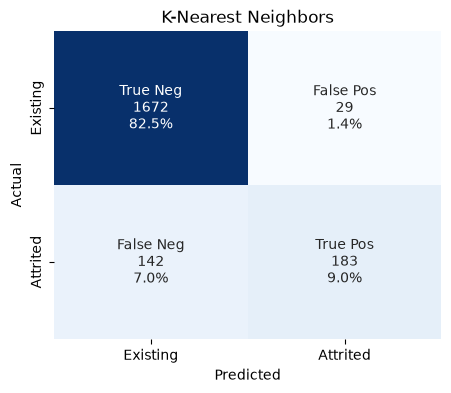

In [14]:
plot_confusion_matrix(result["y_test"], result["y_pred"], title="K-Nearest Neighbors")

## Classification report

In [15]:
print(classification_report(result["y_test"], result["y_pred"], target_names=CLASS_NAMES, digits=4))

              precision    recall  f1-score   support

    Existing     0.9217    0.9830    0.9514      1701
    Attrited     0.8632    0.5631    0.6816       325

    accuracy                         0.9156      2026
   macro avg     0.8925    0.7730    0.8165      2026
weighted avg     0.9123    0.9156    0.9081      2026



## Observations
- Accuracy is high (0.916), but recall for churned customers is only 0.563. The model finds about 56% of customers who churned and misses the rest.
- Precision is good (0.863). When the model says a customer will churn, it is usually correct.
- Compared to the other models so far, KNN has the highest precision but the lowest recall, F1 and MCC. Decision Tree is better on all of these except precision.